# 2. EDA — Article and temporal analysis: catalogue, popularity, categories, freshness, time of day and recency

**BT4222 Group 6 · final project · task 3 (exploratory data analysis), notebook 3 of 3.** Owner: Member 3 (Anh Minh Hoang).
Sections 2, 3, 6 and 7 follow Lee Yong Rui's interim notebooks (article popularity, category exposure, time-of-day and recency dynamics);
section 1 condenses Bao Chau To's and Bryan Ngu's catalogue descriptions.

Questions and the decisions they feed:

| # | Question | Decision it feeds |
|---|---|---|
| 1 | What does the article catalogue look like (categories, text lengths, entities)? | content encoders, category handling, missing-text fallbacks |
| 2 | How concentrated is popularity, and is raw article CTR usable? | popularity features, smoothing, why raw CTR is unreliable |
| 3 | Do categories differ in CTR beyond their exposure? | `category` as a feature for cold-start articles |
| 4 | How fast do articles age, and does time-causal popularity predict clicks? | `article_age_hours`, half-life, prior-click features computed strictly before the impression |
| 5 | How many validation / test articles are new? | the candidate-generation stage must cover unseen articles with content features |
| 6 | Does time of day change volume or engagement? | hour-of-day context feature, calibration versus ranking |
| 7 | Does the time since the previous visit carry signal? | recency feature and its redundancy with hour and history length |

Inputs: `1_Data_Preparation/processed/` (training split; validation and test only in §5). Outputs: `2_EDA/figures/art_*.png`,
`2_EDA/tables/art_*.csv`, `2_EDA/manifest_article_temporal_analysis.json`.

In [1]:
from pathlib import Path
import sys

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

def has_processed(root):
    return (root / "1_Data_Preparation" / "processed" / "candidates_train.parquet").is_file()

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    candidate_roots = [Path("/content/drive/MyDrive/BT4222"), Path("/content/drive/MyDrive/MIND"), Path("/content/drive/MyDrive"), Path("/content")]
else:
    here = Path.cwd()
    candidate_roots = [here, here.parent, here.parent.parent, Path.home() / "BT4222"]
ROOT = next((r for r in candidate_roots if has_processed(r)), None)
if ROOT is None:
    raise FileNotFoundError("Run 1_Data_Preparation/clean_and_validate_data.ipynb first; processed files not found under "
                            + ", ".join(map(str, candidate_roots)))
PROCESSED = ROOT / "1_Data_Preparation" / "processed"
EDA_DIR = ROOT / "2_EDA"
FIG_DIR, TABLE_DIR = EDA_DIR / "figures", EDA_DIR / "tables"
for d in (FIG_DIR, TABLE_DIR):
    d.mkdir(parents=True, exist_ok=True)
print("Environment:", "Google Colab" if IN_COLAB else "local", "| project root:", ROOT)
print("figures ->", FIG_DIR, "| tables ->", TABLE_DIR)

Environment: local | project root: /Users/bryan03/Desktop/BT4222-Group-6-
figures -> /Users/bryan03/Desktop/BT4222-Group-6-/2_EDA/figures | tables -> /Users/bryan03/Desktop/BT4222-Group-6-/2_EDA/tables


In [2]:
NOTEBOOK_NAME = "article_temporal_analysis"

import importlib, subprocess
def ensure(module, pip_name=None):
    try:
        importlib.import_module(module)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name or module])
for _m in ["polars", "pandas", "numpy", "matplotlib", "scipy"]:
    ensure(_m)

import json, time, warnings
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import polars as pl
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.ticker import FuncFormatter, PercentFormatter
from scipy import stats
from IPython.display import display, Markdown
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 180); pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

RUN_STAMP = datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC")
SPLIT = "train"                       # all descriptive figures use the training split (team decision, 1 Oct 2026)

# ---- one visual system for every figure: categorical slots in fixed order, text in ink, grid recessive, one y-axis per panel
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
SERIES = [BLUE, ORANGE, AQUA, YELLOW]
INK, MUTED, GRID, REF = "#0b0b0b", "#52514e", "#e4e4e1", "#8c8b86"
DIVERGING = LinearSegmentedColormap.from_list("div", [ORANGE, "#f2f2ef", BLUE])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "axes.titlesize": 10.5, "axes.titleweight": "semibold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c9c9c5",
    "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True, "legend.frameon": False,
    "legend.fontsize": 8.5, "figure.facecolor": "white",
})
PCT = FuncFormatter(lambda v, _: f"{v:g}%")
THOUSANDS = FuncFormatter(lambda v, _: f"{v/1e6:g}M" if abs(v) >= 1e6 else (f"{v/1e3:g}k" if abs(v) >= 1e3 else f"{v:g}"))

manifest = {"notebook": NOTEBOOK_NAME, "run_stamp": RUN_STAMP, "split": SPLIT, "polars": pl.__version__, "tables": [], "figures": [], "headline": {}}
H = manifest["headline"]
tables = {}

def save_table(name, df):
    if isinstance(df, pl.DataFrame):
        df = df.to_pandas()
    path = TABLE_DIR / f"{name}.csv"
    df.to_csv(path, index=False)
    tables[name] = df
    if path.name not in manifest["tables"]:
        manifest["tables"].append(path.name)
    return df

def save_fig(fig, name, caption=None):
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, bbox_inches="tight")
    if path.name not in manifest["figures"]:
        manifest["figures"].append(path.name)
    plt.show()
    if caption:
        display(Markdown(f"*{name}.png — {caption}*"))

def pct(a, b):
    return 100.0 * a / b if b else float("nan")

def wilson(clicks, n, z=1.96):
    clicks, n = np.asarray(clicks, float), np.asarray(n, float)
    p = clicks / n; denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half

def describe(series, name):
    s = series.drop_nulls()
    q = lambda p: float(s.quantile(p, "nearest"))
    return {"statistic": name, "count": s.len(), "mean": float(s.mean()), "std": float(s.std()), "min": float(s.min()),
            "p5": q(0.05), "p25": q(0.25), "median": q(0.5), "p75": q(0.75), "p95": q(0.95), "p99": q(0.99), "max": float(s.max())}

def bucket(col, edges, labels):
    """Right-closed bins: value <= edges[0] -> labels[0], ..., value > edges[-1] -> labels[-1]."""
    expr = pl.when(pl.col(col) <= edges[0]).then(pl.lit(labels[0]))
    for e, l in zip(edges[1:], labels[1:]):
        expr = expr.when(pl.col(col) <= e).then(pl.lit(l))
    return expr.otherwise(pl.lit(labels[-1]))

def ordered(df, col, order):
    if isinstance(df, pl.DataFrame):
        df = df.to_pandas()
    df[col] = pd.Categorical(df[col], categories=order, ordered=True)
    return df.sort_values(col).reset_index(drop=True)

print("Setup ok ·", RUN_STAMP, "· polars", pl.__version__)

Setup ok · 2026-10-17 08:36 UTC · polars 1.44.2


## 0. Load

In [3]:
t0 = time.time()
imp = pl.read_parquet(PROCESSED / f"impressions_{SPLIT}.parquet", columns=["impression_uid", "user_code", "timestamp", "history_len", "slate_len", "n_clicks"])
cand = pl.read_parquet(PROCESSED / f"candidates_{SPLIT}.parquet", columns=["impression_uid", "user_code", "timestamp", "news_code", "clicked"])
news = pl.read_parquet(PROCESSED / "news_catalogue.parquet").drop(["title", "abstract", "url", "title_entities", "abstract_entities"])
H["n_impressions"], H["n_exposures"], H["n_clicks"] = imp.height, cand.height, int(cand["clicked"].cast(pl.Int64).sum())
H["ctr_overall"] = pct(H["n_clicks"], H["n_exposures"])
T_START, T_END = imp["timestamp"].min(), imp["timestamp"].max()
cat_map = news.select("news_code", pl.col("category").cast(pl.Categorical))
print(f"train: {H['n_impressions']:,} impressions, {H['n_exposures']:,} exposures, CTR {H['ctr_overall']:.2f}%, {T_START} -> {T_END} · loaded in {time.time() - t0:.0f} s")

train: 1,897,835 impressions, 70,314,387 exposures, CTR 4.08%, 2019-11-09 00:00:00 -> 2019-11-14 07:30:28 · loaded in 0 s


## 1. The article catalogue

The training news file holds every article referenced by a training history or slate. Only a quarter of it was ever a candidate inside the
window; the rest exists because users clicked it before the window. Category, title and (usually) abstract are available for every article.

,category,articles,shown,exposures,clicks,subcategories,abstract_pct,entity_pct,article_pct,exposure_pct,click_pct,ctr_pct,exposures_per_shown_article
0,sports,31183,6932,7299419,353525,34,92.5761,94.0352,31.6030,10.3811,12.3222,4.8432,"1,053.0033"
1,news,29528,6531,19691828,872706,38,96.3391,90.7715,29.9257,28.0054,30.4185,4.4318,"3,015.1321"
2,finance,5712,1501,6764892,251948,32,97.6716,80.2171,5.7889,9.6209,8.7817,3.7243,"4,506.9234"
3,travel,4839,1376,3683732,97069,16,92.8704,87.1461,4.9042,5.2389,3.3834,2.6351,"2,677.1308"
4,lifestyle,4451,1600,7674586,306325,53,93.2375,71.5794,4.5110,10.9147,10.6771,3.9914,"4,796.6163"
5,video,4423,1216,1041566,45191,15,99.8643,90.0068,4.4826,1.4813,1.5751,4.3388,856.5510
6,foodanddrink,4298,1243,4322932,128409,16,97.8129,79.0135,4.3559,6.1480,4.4757,2.9704,"3,477.8214"
7,weather,4169,1072,1042291,49369,3,89.6618,86.9753,4.2252,1.4823,1.7208,4.7366,972.2864
8,autos,2994,824,3241208,91294,24,89.7128,82.3313,3.0343,4.6096,3.1821,2.8167,"3,933.5049"
9,health,2859,935,3701912,129919,23,96.0825,63.7286,2.8975,5.2648,4.5284,3.5095,"3,959.2642"


,statistic,count,mean,std,min,p5,p25,median,p75,p95,p99,max
0,title length (words),98671,10.6627,3.2365,1.0000,6.0000,8.0000,10.0000,12.0000,16.0000,20.0000,48.0000
1,"abstract length (words, when present)",93411,38.2798,26.2183,1.0000,8.0000,17.0000,27.0000,67.0000,78.0000,84.0000,474.0000
2,entities in title,98671,1.1920,0.9758,0.0000,0.0000,0.0000,1.0000,2.0000,3.0000,4.0000,9.0000
3,entities in abstract,98671,1.9652,1.8863,0.0000,0.0000,0.0000,2.0000,3.0000,6.0000,8.0000,30.0000


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


98,671 articles in the training news file, 24,641 shown; 18 categories (16 ever shown), 283 subcategories (117 with < 10 articles); abstract missing 5.3%, no entity at all 11.7%; median title 10 words (p99 20), median abstract 27 words (p99 83)


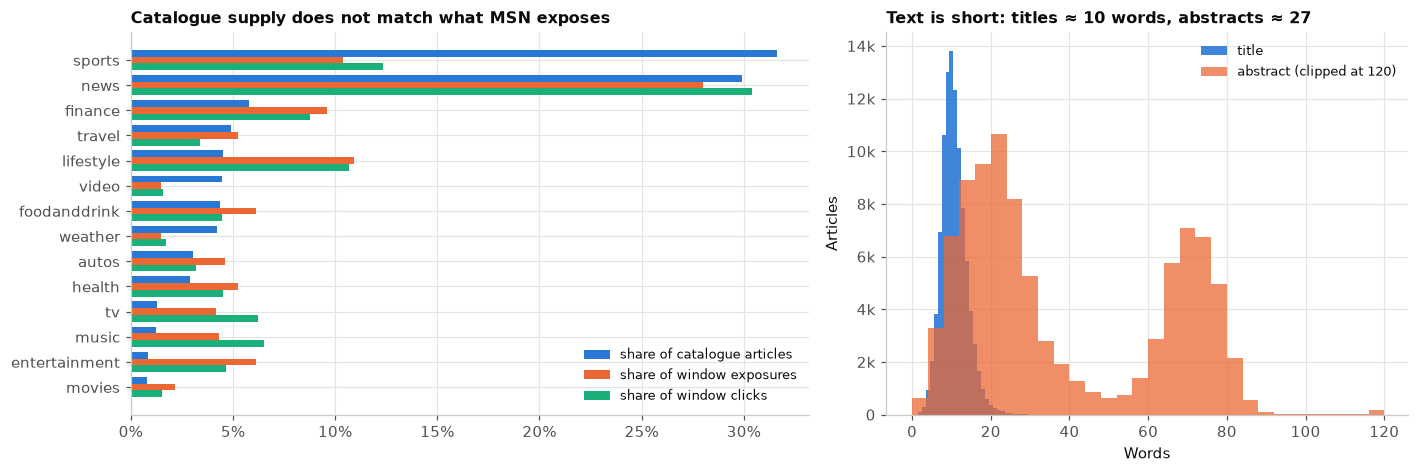

*art_01_catalogue.png — Catalogue composition and text lengths, training news file.*

In [4]:
tr = news.filter(pl.col("in_news_train"))
H["catalogue_train"], H["shown_train"] = tr.height, int((tr["exposures_train"] > 0).sum())
by_cat = (tr.group_by("category").agg(articles=pl.len(), shown=(pl.col("exposures_train") > 0).sum(), exposures=pl.col("exposures_train").sum(), clicks=pl.col("clicks_train").sum(),
                                      subcategories=pl.col("subcategory").n_unique(), abstract_pct=100 * pl.col("has_abstract").mean(), entity_pct=100 * ((pl.col("n_title_entities") + pl.col("n_abstract_entities")) > 0).mean())
          .with_columns(article_pct=100 * pl.col("articles") / pl.col("articles").sum(), exposure_pct=100 * pl.col("exposures") / pl.col("exposures").sum(),
                        click_pct=100 * pl.col("clicks") / pl.col("clicks").sum(), ctr_pct=100 * pl.col("clicks") / pl.col("exposures"),
                        exposures_per_shown_article=pl.col("exposures") / pl.col("shown")).sort("articles", descending=True).to_pandas())
display(save_table("art_01_catalogue_by_category", by_cat))
H["categories_in_file"], H["categories_shown"] = int(tr["category"].n_unique()), int(tr.filter(pl.col("exposures_train") > 0)["category"].n_unique())
sub = tr.group_by("subcategory").agg(articles=pl.len()).sort("articles", descending=True)
H["subcategories"], H["subcategories_under_10"] = sub.height, int((sub["articles"] < 10).sum())
text = pd.DataFrame([describe(tr["title_len_words"], "title length (words)"), describe(tr.filter(pl.col("has_abstract"))["abstract_len_words"], "abstract length (words, when present)"),
                     describe(tr["n_title_entities"], "entities in title"), describe(tr["n_abstract_entities"], "entities in abstract")])
display(save_table("art_01_text_lengths", text))
H.update(abstract_missing_pct=100 * (1 - float(tr["has_abstract"].mean())), title_median_words=float(tr["title_len_words"].median()), abstract_median_words=float(tr.filter(pl.col("has_abstract"))["abstract_len_words"].median()),
         no_entity_pct=100 * float(((tr["n_title_entities"] + tr["n_abstract_entities"]) == 0).mean()), title_p99_words=float(tr["title_len_words"].quantile(0.99)), abstract_p99_words=float(tr["abstract_len_words"].quantile(0.99)))
print(f"{H['catalogue_train']:,} articles in the training news file, {H['shown_train']:,} shown; {H['categories_in_file']} categories ({H['categories_shown']} ever shown), {H['subcategories']} subcategories "
      f"({H['subcategories_under_10']} with < 10 articles); abstract missing {H['abstract_missing_pct']:.1f}%, no entity at all {H['no_entity_pct']:.1f}%; "
      f"median title {H['title_median_words']:.0f} words (p99 {H['title_p99_words']:.0f}), median abstract {H['abstract_median_words']:.0f} words (p99 {H['abstract_p99_words']:.0f})")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.3, 1]})
top = by_cat.head(14).iloc[::-1]; y = np.arange(len(top)); w = 0.27
axes[0].barh(y + w, top.article_pct, height=w, color=BLUE, label="share of catalogue articles")
axes[0].barh(y, top.exposure_pct, height=w, color=ORANGE, label="share of window exposures")
axes[0].barh(y - w, top.click_pct, height=w, color=AQUA, label="share of window clicks")
axes[0].set_yticks(y); axes[0].set_yticklabels(top.category); axes[0].xaxis.set_major_formatter(PCT); axes[0].legend(loc="lower right"); axes[0].set_title("Catalogue supply does not match what MSN exposes")
axes[1].hist(tr["title_len_words"].to_numpy(), bins=np.arange(0, 31) - 0.5, color=BLUE, label="title", alpha=0.9)
ab = tr.filter(pl.col("has_abstract"))["abstract_len_words"].to_numpy()
axes[1].hist(np.clip(ab, 0, 120), bins=np.arange(0, 121, 4), color=ORANGE, label="abstract (clipped at 120)", alpha=0.75)
axes[1].set_xlabel("Words"); axes[1].set_ylabel("Articles"); axes[1].yaxis.set_major_formatter(THOUSANDS); axes[1].legend(); axes[1].set_title("Text is short: titles ≈ 10 words, abstracts ≈ 27")
fig.tight_layout(); save_fig(fig, "art_01_catalogue", "Catalogue composition and text lengths, training news file.")

**Reading.** Sports is a third of the catalogue but a tenth of exposures; news, lifestyle and sports together carry half of the exposures. Titles
are short (median 10 words, 99 % within 20); abstracts have a median of 27 words, are missing for 5 % and are bimodal (a short-summary mode
near 20 words and a long mode near 70). A quarter of articles have no title entity and 12 % have no linked entity at all. 117 of 283
subcategories have fewer than ten articles.

**Implications.** A title-first text encoder with a short maximum length (20 tokens for titles, 100 for abstracts) covers 99 % of the text; the
abstract needs a mask or title fallback; entity features need a text-only path. Subcategories must be merged or embedded, not one-hot
encoded. Exposure shares are MSN's editorial choice, not demand, so catalogue shares cannot be read as user preference.

## 2. Article popularity

One row per article shown in the window: exposures, clicks and CTR over the whole training window. These are retrospective totals; the
features derived from them later must be computed from events before each impression.

,statistic,count,mean,std,min,p5,p25,median,p75,p95,p99,max
0,exposures per shown article,24641,"2,853.5525","13,645.1816",1.0000,1.0000,9.0000,46.0000,215.0000,"14,134.0000","66,121.0000","331,542.0000"
1,clicks per shown article,24641,116.4319,"1,041.8792",0.0000,0.0000,0.0000,1.0000,8.0000,349.0000,"2,251.0000","60,638.0000"
2,article CTR (%),24641,4.1094,7.8509,0.0000,0.0000,0.0000,1.7836,5.1724,15.4217,33.3333,100.0000


,bucket,articles,exposures,clicks,never_clicked_pct,article_pct,exposure_pct,click_pct,ctr_pct
0,<10,6223,22113,833,88.4139,25.2547,0.0314,0.0290,3.7670
1,10-99,9488,379506,17715,37.1100,38.5049,0.5397,0.6175,4.6679
2,100-999,5610,1658007,68384,5.8111,22.7669,2.3580,2.3835,4.1245
3,1k-10k,1816,7064831,222415,0.0000,7.3698,10.0475,7.7524,3.1482
4,10k+,1504,61189930,2559651,0.0000,6.1036,87.0233,89.2176,4.1831


162 articles = 50% of clicks, 747 (3.0% of 24,641) = 80%, 1,356 = 90%; Gini 0.96; 37.9% of shown articles never clicked


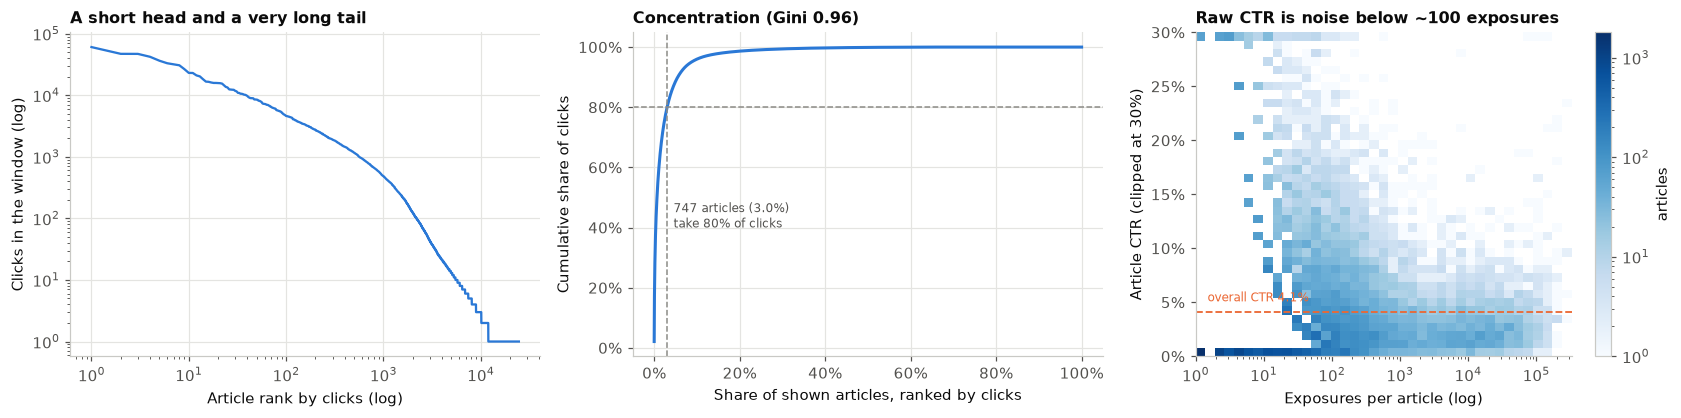

*art_02_popularity.png — Article popularity concentration and the instability of raw article CTR, training split.*

In [5]:
art = tr.filter(pl.col("exposures_train") > 0).select("news_code", "category", exposures=pl.col("exposures_train"), clicks=pl.col("clicks_train")).with_columns(ctr_pct=100 * pl.col("clicks") / pl.col("exposures"))
display(save_table("art_02_article_level_summary", pd.DataFrame([describe(art["exposures"], "exposures per shown article"), describe(art["clicks"], "clicks per shown article"), describe(art["ctr_pct"], "article CTR (%)")])))
ranked = art.sort("clicks", descending=True).with_columns(cum_clicks=pl.col("clicks").cum_sum()).with_columns(cum_click_pct=100 * pl.col("cum_clicks") / pl.col("clicks").sum()).with_row_index("rank", offset=1)
def articles_for(share):
    return int(ranked.filter(pl.col("cum_click_pct") >= share)["rank"].min())
H["articles_for_50_pct_clicks"], H["articles_for_80_pct_clicks"], H["articles_for_90_pct_clicks"] = articles_for(50), articles_for(80), articles_for(90)
cl = np.sort(art["clicks"].to_numpy().astype(float)); n = len(cl)
H["gini_clicks"] = float((2 * np.sum(np.arange(1, n + 1) * cl) / (n * cl.sum())) - (n + 1) / n)
H["never_clicked_pct"] = 100 * float((art["clicks"] == 0).mean())
buckets = ["<10", "10-99", "100-999", "1k-10k", "10k+"]
pop = (art.with_columns(bucket=bucket("exposures", [9, 99, 999, 9999], buckets)).group_by("bucket").agg(articles=pl.len(), exposures=pl.col("exposures").sum(), clicks=pl.col("clicks").sum(), never_clicked_pct=100 * (pl.col("clicks") == 0).mean())
       .with_columns(article_pct=100 * pl.col("articles") / pl.col("articles").sum(), exposure_pct=100 * pl.col("exposures") / pl.col("exposures").sum(), click_pct=100 * pl.col("clicks") / pl.col("clicks").sum(), ctr_pct=100 * pl.col("clicks") / pl.col("exposures")))
pop = ordered(pop, "bucket", buckets); display(save_table("art_02_popularity_buckets", pop)); H["popularity_buckets"] = pop.round(3).to_dict("records")
print(f"{H['articles_for_50_pct_clicks']:,} articles = 50% of clicks, {H['articles_for_80_pct_clicks']:,} ({pct(H['articles_for_80_pct_clicks'], art.height):.1f}% of {art.height:,}) = 80%, {H['articles_for_90_pct_clicks']:,} = 90%; "
      f"Gini {H['gini_clicks']:.2f}; {H['never_clicked_pct']:.1f}% of shown articles never clicked")

fig, axes = plt.subplots(1, 3, figsize=(15.5, 3.9))
r = ranked.to_pandas()
axes[0].plot(r["rank"], r["clicks"].clip(lower=1), color=BLUE, lw=1.5)
axes[0].set_xscale("log"); axes[0].set_yscale("log"); axes[0].set_xlabel("Article rank by clicks (log)"); axes[0].set_ylabel("Clicks in the window (log)"); axes[0].set_title("A short head and a very long tail")
axes[1].plot(100 * r["rank"] / art.height, r["cum_click_pct"], color=BLUE, lw=2)
axes[1].axhline(80, color=REF, ls="--", lw=1); axes[1].axvline(100 * H["articles_for_80_pct_clicks"] / art.height, color=REF, ls="--", lw=1)
axes[1].text(100 * H["articles_for_80_pct_clicks"] / art.height + 1.5, 40, f"{H['articles_for_80_pct_clicks']:,} articles ({pct(H['articles_for_80_pct_clicks'], art.height):.1f}%)\ntake 80% of clicks", fontsize=8, color=MUTED)
axes[1].set_xlabel("Share of shown articles, ranked by clicks"); axes[1].set_ylabel("Cumulative share of clicks"); axes[1].xaxis.set_major_formatter(PCT); axes[1].yaxis.set_major_formatter(PCT); axes[1].set_title(f"Concentration (Gini {H['gini_clicks']:.2f})")
e = art["exposures"].to_numpy(); ct = art["ctr_pct"].to_numpy()
hb = axes[2].hist2d(e, np.clip(ct, 0, 30), bins=[np.logspace(0, np.log10(e.max()), 40), np.linspace(0, 30, 40)], cmap="Blues", norm=LogNorm())
axes[2].axhline(H["ctr_overall"], color=ORANGE, ls="--", lw=1.2); axes[2].text(1.5, H["ctr_overall"] + 1, f"overall CTR {H['ctr_overall']:.1f}%", color=ORANGE, fontsize=8)
axes[2].set_xscale("log"); axes[2].set_xlabel("Exposures per article (log)"); axes[2].set_ylabel("Article CTR (clipped at 30%)"); axes[2].yaxis.set_major_formatter(PCT); axes[2].grid(False)
fig.colorbar(hb[3], ax=axes[2], label="articles"); axes[2].set_title("Raw CTR is noise below ~100 exposures")
fig.tight_layout(); save_fig(fig, "art_02_popularity", "Article popularity concentration and the instability of raw article CTR, training split.")

**Reading.** Popularity is extremely concentrated: 3 % of shown articles collect 80 % of clicks (Gini 0.96), the median article has 46
exposures and one click, and 38 % of shown articles are never clicked. Article CTR scatters wildly below a hundred exposures and
converges towards the overall 4 % as exposure grows.

**Implications.** Popularity is a strong candidate signal but exposure counts reflect MSN's exposure policy as much as appeal. Use
**prior exposures, prior clicks and a smoothed prior CTR** (Bayesian shrinkage towards the category or global rate), all computed from events
before the impression (§4 shows the time-causal version works). Raw whole-window CTR is neither reliable nor leak-free.

## 3. Category engagement

Category is available for every article, including cold-start ones. The risk is confounding: category CTR may reflect which articles (and how
much exposure) each category contains. The second view compares categories inside exposure buckets.

,category,bucket,exposures,clicks,ctr_pct,bucket_ctr_pct,dev_pp
0,health,10-99,8349,256,3.0662,4.6679,-1.6017
1,health,100-999,53567,1566,2.9234,4.1245,-1.2010
2,lifestyle,10k+,7052953,290952,4.1253,4.1831,-0.0579
3,foodanddrink,10-99,15311,494,3.2264,4.6679,-1.4415
4,finance,10k+,6032777,235616,3.9056,4.1831,-0.2775
5,news,10-99,97617,4280,4.3845,4.6679,-0.2834
6,health,1k-10k,591629,16229,2.7431,3.1482,-0.4051
7,travel,10k+,3321151,87926,2.6475,4.1831,-1.5357
8,sports,100-999,383960,21407,5.5753,4.1245,1.4509
9,news,100-999,526191,21862,4.1548,4.1245,0.0303


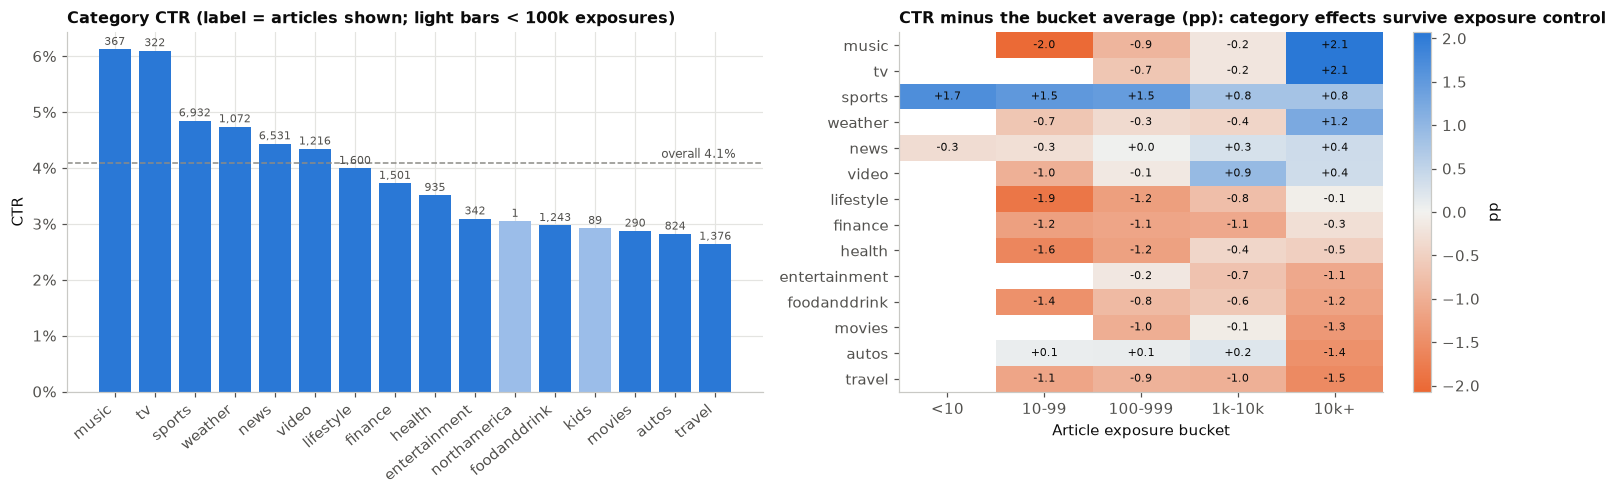

*art_03_category_ctr.png — Category CTR, raw and relative to articles with similar exposure, training split.*

In [6]:
cat_ctr = by_cat[by_cat.exposures > 0].sort_values("ctr_pct", ascending=False)
H["category_ctr"] = dict(zip(cat_ctr.category, cat_ctr.ctr_pct.round(2)))
cell = (art.with_columns(bucket=bucket("exposures", [9, 99, 999, 9999], buckets)).group_by("category", "bucket").agg(exposures=pl.col("exposures").sum(), clicks=pl.col("clicks").sum())
        .with_columns(ctr_pct=100 * pl.col("clicks") / pl.col("exposures")))
bucket_ctr = cell.group_by("bucket").agg(bucket_ctr_pct=100 * pl.col("clicks").sum() / pl.col("exposures").sum())
dev = (cell.join(bucket_ctr, on="bucket").with_columns(dev_pp=pl.col("ctr_pct") - pl.col("bucket_ctr_pct")).filter(pl.col("exposures") >= 5_000)).to_pandas()
major = cat_ctr[cat_ctr.exposures >= 100_000].category.tolist()
heat = dev[dev.category.isin(major)].pivot(index="category", columns="bucket", values="dev_pp").reindex(index=major, columns=buckets)
display(save_table("art_03_category_ctr_by_exposure_bucket", dev))
H["category_always_above_bucket"] = [c_ for c_ in major if (heat.loc[c_].dropna() > 0).all()]
H["category_always_below_bucket"] = [c_ for c_ in major if (heat.loc[c_].dropna() < 0).all()]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.15, 1]})
cols = [BLUE if c_ in major else "#9bbde9" for c_ in cat_ctr.category]
axes[0].bar(cat_ctr.category, cat_ctr.ctr_pct, color=cols)
axes[0].axhline(H["ctr_overall"], color=REF, ls="--", lw=1); axes[0].text(len(cat_ctr) - 0.5, H["ctr_overall"] + 0.1, f"overall {H['ctr_overall']:.1f}%", ha="right", fontsize=8, color=MUTED)
for i, row in enumerate(cat_ctr.itertuples()):
    axes[0].text(i, row.ctr_pct + 0.08, f"{row.shown:,}", ha="center", fontsize=7, color=MUTED)
axes[0].set_xticks(range(len(cat_ctr))); axes[0].set_xticklabels(cat_ctr.category, rotation=40, ha="right"); axes[0].set_ylabel("CTR"); axes[0].yaxis.set_major_formatter(PCT)
axes[0].set_title("Category CTR (label = articles shown; light bars < 100k exposures)")
vlim = np.nanmax(np.abs(heat.values))
im = axes[1].imshow(heat.values, cmap=DIVERGING, vmin=-vlim, vmax=vlim, aspect="auto")
axes[1].set_xticks(range(len(buckets))); axes[1].set_xticklabels(buckets); axes[1].set_yticks(range(len(major))); axes[1].set_yticklabels(major); axes[1].grid(False)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        if not np.isnan(v): axes[1].text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=7.5, color=INK)
axes[1].set_xlabel("Article exposure bucket"); axes[1].set_title("CTR minus the bucket average (pp): category effects survive exposure control")
fig.colorbar(im, ax=axes[1], label="pp")
fig.tight_layout(); save_fig(fig, "art_03_category_ctr", "Category CTR, raw and relative to articles with similar exposure, training split.")

**Reading.** Category CTR spans 2.6 % (travel) to about 6 % (music, tv), and most of the spread survives when articles are compared with
others of similar exposure: sports stays above its bucket average in every bucket, while travel, movies, food and drink, finance and lifestyle
stay below. Music and tv earn their edge mainly on heavily exposed articles.

**Implications.** Keep `category` as a feature: it survives exposure control, spans a 2.3× range and is one of the few signals available for
cold-start articles. Encode it compactly (16 shown categories; merge the near-empty ones) and let the model learn category × user-affinity
interactions rather than hand-coding them.

## 4. Freshness and time-causal popularity

Article age is measured from the article's first recorded exposure in the training window; articles already present in the first hours of the
log are older than that (left-censored). Prior popularity is computed strictly before the impression: the article's clicks in all completed
hours before the current one.

,censored,age_bin,exposures,clicks,ctr_pct,exposure_pct
1,False,<1h,215624,12715,5.8968,0.3067
3,False,1-3h,731213,35491,4.8537,1.0399
4,False,3-6h,1248177,59859,4.7957,1.7751
6,False,6-12h,3517337,158238,4.4988,5.0023
8,False,12-24h,32199712,1455185,4.5192,45.7939
11,False,24-48h,12138326,518156,4.2688,17.2629
13,False,48-72h,2148984,52934,2.4632,3.0563
15,False,>72h,981322,28729,2.9276,1.3956
0,True,<1h,97771,3748,3.8334,0.1390
2,True,1-3h,242994,9721,4.0005,0.3456


,category,articles_shown,median_h,p25_h,p75_h,articles_10plus,median_h_10plus
0,video,1216,3.8382,1.1222,14.7106,846,6.1199
1,sports,6932,10.0647,3.0022,20.4825,5317,13.3197
2,news,6531,12.6967,3.7347,24.5181,5082,15.5272
3,weather,1072,13.4453,4.4944,24.9686,896,16.2885
4,travel,1376,14.5142,3.8375,28.5553,1005,17.8431
5,music,367,15.3242,5.3528,44.2350,319,15.4292
6,finance,1501,18.0131,5.2983,54.8256,1126,23.4387
7,foodanddrink,1243,22.5575,5.6628,63.0381,889,26.3139
8,autos,824,28.3899,6.5675,79.5403,555,34.6050
9,lifestyle,1600,28.4133,7.0472,77.5706,1036,38.5067


,prior_bin,exposures,clicks,ctr_pct,exposure_pct
0,0,1156697,37766,3.2650,1.6450
1,1-9,3850485,123397,3.2047,5.4761
2,10-99,12591308,353586,2.8082,17.9072
3,100-999,29565746,925119,3.1290,42.0479
4,1000+,23150151,1429130,6.1733,32.9238


24% of exposures are on articles already present in the first 6 h (age censored) · 8 s


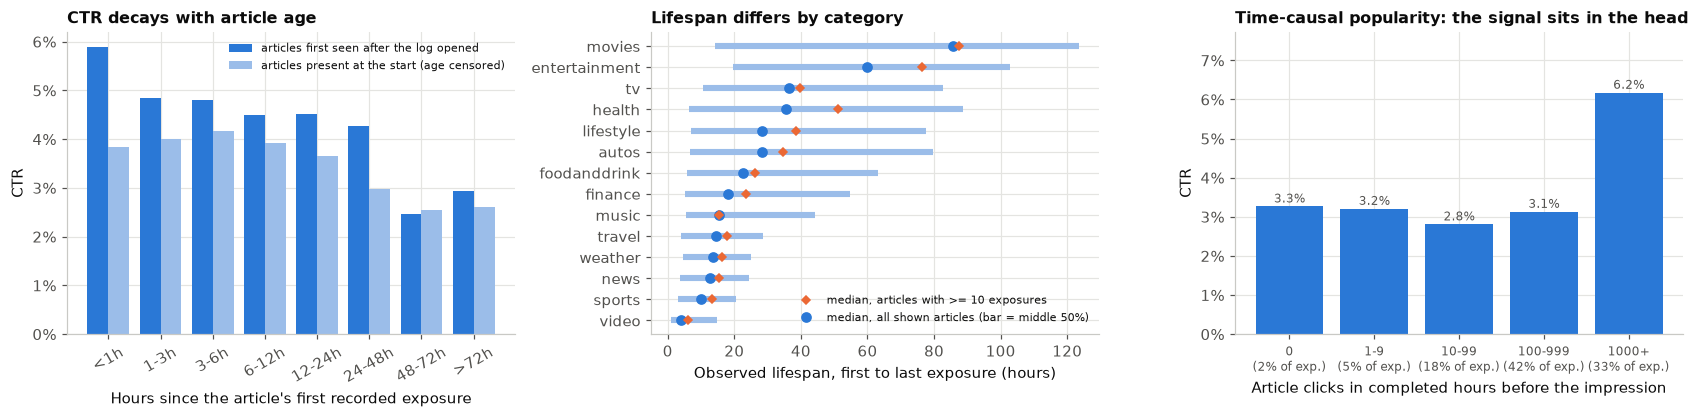

*art_04_freshness_popularity.png — Article age, lifespan and time-causal prior popularity, training split.*

In [7]:
t0 = time.time()
first_seen = tr.select("news_code", "first_exposure_train", "last_exposure_train", "exposures_train")
CENSOR_HOURS = 6
age = (cand.lazy().join(first_seen.lazy(), on="news_code", how="left")
       .with_columns(age_h=(pl.col("timestamp") - pl.col("first_exposure_train")).dt.total_seconds() / 3600,
                     censored=pl.col("first_exposure_train") < (T_START + pd.Timedelta(hours=CENSOR_HOURS)))
       .with_columns(age_bin=bucket("age_h", [1, 3, 6, 12, 24, 48, 72], ["<1h", "1-3h", "3-6h", "6-12h", "12-24h", "24-48h", "48-72h", ">72h"])))
AGE_ORDER = ["<1h", "1-3h", "3-6h", "6-12h", "12-24h", "24-48h", "48-72h", ">72h"]
age_tbl = (age.group_by("censored", "age_bin").agg(exposures=pl.len(), clicks=pl.col("clicked").cast(pl.Int64).sum()).with_columns(ctr_pct=100 * pl.col("clicks") / pl.col("exposures")).collect())
age_tbl = ordered(age_tbl, "age_bin", AGE_ORDER).sort_values(["censored", "age_bin"]); age_tbl["exposure_pct"] = 100 * age_tbl.exposures / age_tbl.exposures.sum()
display(save_table("art_04_ctr_by_article_age", age_tbl))
fresh = age_tbl[~age_tbl.censored]
H["censored_exposure_pct"] = float(age_tbl[age_tbl.censored].exposure_pct.sum())
H["ctr_by_age_uncensored"] = dict(zip(fresh.age_bin.astype(str), fresh.ctr_pct.round(2)))
# lifespan by category (first to last exposure), shown articles only
# lifespan = first to last recorded exposure. Two cohorts: every shown article (the definition used in the interim report,
# section 3.7.5) and articles with at least 10 exposures (single-exposure articles have a zero span by construction)
life_h = (pl.col("last_exposure_train") - pl.col("first_exposure_train")).dt.total_seconds() / 3600
life_all = (tr.filter(pl.col("exposures_train") > 0).with_columns(life_h=life_h).group_by("category")
            .agg(articles_shown=pl.len(), median_h=pl.col("life_h").median(), p25_h=pl.col("life_h").quantile(0.25), p75_h=pl.col("life_h").quantile(0.75)))
life_10 = (tr.filter(pl.col("exposures_train") >= 10).with_columns(life_h=life_h).group_by("category")
           .agg(articles_10plus=pl.len(), median_h_10plus=pl.col("life_h").median()))
life = life_all.join(life_10, on="category", how="left").filter(pl.col("articles_shown") >= 100).sort("median_h")
display(save_table("art_04_lifespan_by_category", life))
H["lifespan_median_h_all_shown"] = dict(zip(life["category"].to_list(), [round(v, 1) for v in life["median_h"].to_list()]))
H["lifespan_median_h_10plus"] = dict(zip(life["category"].to_list(), [round(v, 1) for v in life["median_h_10plus"].to_list()]))
# time-causal popularity: clicks in completed hours before the impression
hour_idx = ((pl.col("timestamp") - pl.lit(T_START)).dt.total_seconds() // 3600).cast(pl.Int32)
hourly = (cand.lazy().select("news_code", hour_idx.alias("h"), "clicked").group_by("news_code", "h").agg(c=pl.col("clicked").cast(pl.Int64).sum()).sort("news_code", "h")
          .with_columns(prior_clicks=pl.col("c").cum_sum().over("news_code") - pl.col("c")))     # clicks strictly before this hour
prior = (cand.lazy().select("news_code", hour_idx.alias("h"), "clicked").join(hourly.select("news_code", "h", "prior_clicks"), on=["news_code", "h"], how="left")
         .with_columns(bucket("prior_clicks", [0, 9, 99, 999], ["0", "1-9", "10-99", "100-999", "1000+"]).alias("prior_bin"))
         .group_by("prior_bin").agg(exposures=pl.len(), clicks=pl.col("clicked").cast(pl.Int64).sum()).with_columns(ctr_pct=100 * pl.col("clicks") / pl.col("exposures")).collect())
prior = ordered(prior, "prior_bin", ["0", "1-9", "10-99", "100-999", "1000+"]); prior["exposure_pct"] = 100 * prior.exposures / prior.exposures.sum()
display(save_table("art_04_ctr_by_prior_clicks", prior)); H["ctr_by_prior_clicks"] = dict(zip(prior.prior_bin.astype(str), prior.ctr_pct.round(2)))
print(f"{H['censored_exposure_pct']:.0f}% of exposures are on articles already present in the first {CENSOR_HOURS} h (age censored) · {time.time() - t0:.0f} s")

fig, axes = plt.subplots(1, 3, figsize=(15.5, 3.9))
x = np.arange(len(AGE_ORDER))
axes[0].bar(x - 0.2, fresh.set_index("age_bin").reindex(AGE_ORDER).ctr_pct, width=0.4, color=BLUE, label="articles first seen after the log opened")
cens = age_tbl[age_tbl.censored].set_index("age_bin").reindex(AGE_ORDER)
axes[0].bar(x + 0.2, cens.ctr_pct, width=0.4, color="#9bbde9", label="articles present at the start (age censored)")
axes[0].set_xticks(x); axes[0].set_xticklabels(AGE_ORDER, rotation=30); axes[0].set_xlabel("Hours since the article's first recorded exposure"); axes[0].set_ylabel("CTR"); axes[0].yaxis.set_major_formatter(PCT)
axes[0].legend(fontsize=7.5); axes[0].set_title("CTR decays with article age")
lp = life.to_pandas()
axes[1].hlines(range(len(lp)), lp.p25_h, lp.p75_h, color="#9bbde9", lw=4); axes[1].plot(lp.median_h, range(len(lp)), "o", color=BLUE)
axes[1].plot(lp.median_h_10plus, range(len(lp)), "D", ms=4, color=ORANGE, label="median, articles with >= 10 exposures")
axes[1].plot([], [], "o", color=BLUE, label="median, all shown articles (bar = middle 50%)")
axes[1].set_yticks(range(len(lp))); axes[1].set_yticklabels(lp.category); axes[1].set_xlabel("Observed lifespan, first to last exposure (hours)"); axes[1].legend(loc="lower right", fontsize=7.5); axes[1].set_title("Lifespan differs by category")
xl = [f"{b}\n({s:.0f}% of exp.)" for b, s in zip(prior.prior_bin.astype(str), prior.exposure_pct)]
axes[2].bar(range(len(prior)), prior.ctr_pct, color=BLUE)
for i, v in enumerate(prior.ctr_pct): axes[2].text(i, v + 0.1, f"{v:.1f}%", ha="center", fontsize=8, color=MUTED)
axes[2].set_xticks(range(len(prior))); axes[2].set_xticklabels(xl, fontsize=8)
axes[2].set_xlabel("Article clicks in completed hours before the impression"); axes[2].set_ylabel("CTR"); axes[2].yaxis.set_major_formatter(PCT); axes[2].set_ylim(0, prior.ctr_pct.max() * 1.25)
axes[2].set_title("Time-causal popularity: the signal sits in the head")
fig.tight_layout(); save_fig(fig, "art_04_freshness_popularity", "Article age, lifespan and time-causal prior popularity, training split.")

**Reading.** For articles first seen after the log opened, CTR falls from 5.9 % in the first hour to about 2.5 % after two days; articles
already present when the log opened (age unknown, 24 % of exposures) sit at the low end throughout. Lifespans differ by category: over all shown
articles the median runs from 4 hours (video) to 28 hours (lifestyle), the definition used in the interim report; restricting to articles with at
least 10 exposures lengthens every median (video 6 h, lifestyle 39 h) because single-exposure articles have a zero span. Prior clicks are informative mainly at the head: articles with 1,000 or more clicks before the
impression (a third of exposures) are clicked at 6.2 %, everything below sits near 3 %; the relation is not monotonic because articles with no
prior click are brand new and benefit from the freshness effect.

**Implications.** `article_age_hours` (from first observed exposure, with a censoring indicator) and a category-specific decay are justified
features. Popularity must be **time-causal**: prior exposures and prior clicks in completed hours, plus a smoothed prior CTR, and it must be
modelled jointly with age because the two work against each other for new articles; the previous group's ablation showed that whole-window
popularity leaks and hurts ranking. New articles (prior clicks = 0) need content and category.

## 5. Cold-start articles in validation and test

An article is cold for the model when it was never shown in the training window. The split is by time, so later days naturally contain
new articles; the test day is a full day later than the end of validation.

,status,articles,exposures,clicks,split,exposure_pct,click_pct,ctr_pct
0,absent from train,3658,9661666,431683,test,68.5927,75.0955,4.4680
1,in train histories only,31,157876,4258,test,1.1208,0.7407,2.6971
2,shown in train,3308,4266015,138904,test,30.2864,24.1637,3.2561
3,absent from train,2375,612171,28581,validation,4.6401,5.5534,4.6688
4,in train histories only,30,46783,1793,validation,0.3546,0.3484,3.8326
5,shown in train,5623,12534033,484284,validation,95.0053,94.0982,3.8638


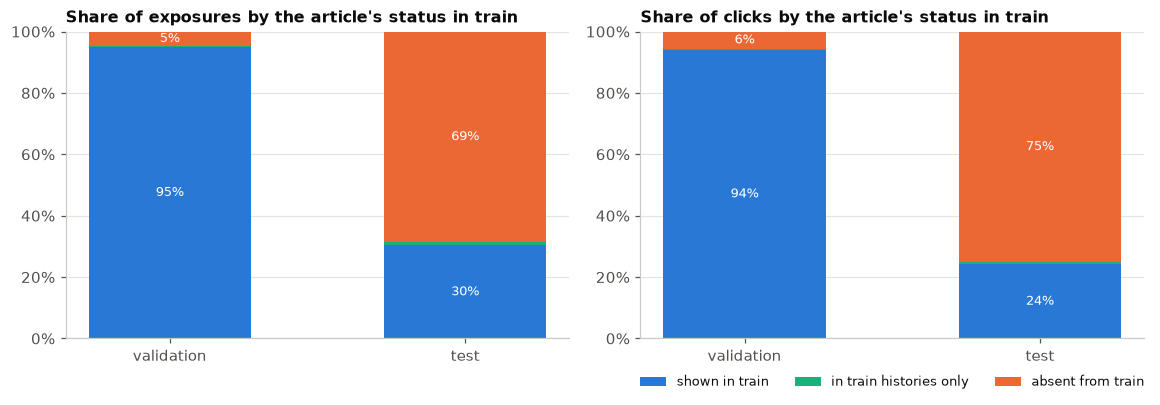

*art_05_cold_start_articles.png — Validation and test exposures on articles unseen in the training window.*

In [8]:
rows = []
for sp in ["validation", "test"]:
    cs = pl.read_parquet(PROCESSED / f"candidates_{sp}.parquet", columns=["news_code", "clicked"]).join(news.select("news_code", "exposures_train", "in_news_train", "category"), on="news_code", how="left")
    cs = cs.with_columns(status=pl.when(pl.col("exposures_train") > 0).then(pl.lit("shown in train")).when(pl.col("in_news_train")).then(pl.lit("in train histories only")).otherwise(pl.lit("absent from train")))
    g = cs.group_by("status").agg(articles=pl.col("news_code").n_unique(), exposures=pl.len(), clicks=pl.col("clicked").cast(pl.Int64).sum()).with_columns(split=pl.lit(sp))
    rows.append(g)
cold_art = (pl.concat(rows).with_columns(exposure_pct=100 * pl.col("exposures") / pl.col("exposures").sum().over("split"), click_pct=100 * pl.col("clicks") / pl.col("clicks").sum().over("split"),
                                         ctr_pct=100 * pl.col("clicks") / pl.col("exposures")).sort("split", "status").to_pandas())
display(save_table("art_05_cold_start_articles", cold_art)); H["cold_start_articles"] = cold_art.round(3).to_dict("records")
STAT = ["shown in train", "in train histories only", "absent from train"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, metric, title in [(axes[0], "exposure_pct", "Share of exposures"), (axes[1], "click_pct", "Share of clicks")]:
    piv = cold_art.pivot(index="split", columns="status", values=metric).reindex(["validation", "test"])[STAT].fillna(0)
    bottom = np.zeros(2)
    for s_, col in zip(STAT, [BLUE, AQUA, ORANGE]):
        ax.bar(piv.index, piv[s_], bottom=bottom, color=col, label=s_, width=0.55)
        for i, v in enumerate(piv[s_]):
            if v > 4: ax.text(i, bottom[i] + v / 2, f"{v:.0f}%", ha="center", va="center", fontsize=8.5, color="white")
        bottom += piv[s_].values
    ax.set_ylim(0, 100); ax.yaxis.set_major_formatter(PCT); ax.set_title(title + " by the article's status in train")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3)
fig.tight_layout(); save_fig(fig, "art_05_cold_start_articles", "Validation and test exposures on articles unseen in the training window.")

**Reading.** On the validation afternoon 95 % of exposures still fall on articles shown in train, but on the test day 70 % of exposures and
76 % of clicks are on articles that were never a candidate in train, almost all of them absent from the training news file altogether.

**Implications.** The candidate-generation stage cannot rely on item ids or on in-window popularity alone: on the test day it would miss
three quarters of the clicks. Content representations (title, category, entities) and a time-causal popularity that updates through the test day are
required, and `available_from` filtering must treat test-day articles as eligible from their first appearance.

## 6. Time of day

Volume and engagement over the window, then by hour of the log clock (timezone undocumented). Because CTR tracks slate length, engagement
is measured as clicks per impression; to separate a time effect from who is online, each user's series is centred on the user's own mean.

,date,impressions,users,clicks,exposures,ctr_pct
0,2019-11-09,192552,139745,290054,7544547,3.8446
1,2019-11-10,212343,150620,311416,7496213,4.1543
2,2019-11-11,464467,301585,683491,16583216,4.1216
3,2019-11-12,478375,314303,734806,16744834,4.3883
4,2019-11-13,453494,299936,692845,17738458,3.9059
5,2019-11-14,96604,83384,156386,4207119,3.7172


,hour,impressions,clicks,exposures,within_user_dev,impression_pct,clicks_per_impression,ctr_pct,raw_dev,adjusted_ctr_pct,raw_ctr_dev_pp,adjusted_ctr_dev_pp
0,0,15071,22840,572566,0.0089,0.7941,1.5155,3.9891,0.0038,3.9711,-0.0912,-0.1091
1,1,16448,25471,639407,0.0327,0.8667,1.5486,3.9835,0.0369,3.9595,-0.0967,-0.1207
2,2,24847,38394,967568,0.0296,1.3092,1.5452,3.9681,0.0335,3.9354,-0.1122,-0.1449
3,3,44167,69632,1749417,0.0368,2.3272,1.5766,3.9803,0.0648,3.9611,-0.0999,-0.1191
4,4,77672,124150,3185809,0.0475,4.0927,1.5984,3.8970,0.0867,3.8919,-0.1833,-0.1884
5,5,122882,194899,4909997,0.0372,6.4749,1.5861,3.9694,0.0743,3.9887,-0.1108,-0.0916
6,6,152483,237181,5840226,0.0142,8.0346,1.5555,4.0612,0.0437,4.0698,-0.0191,-0.0105
7,7,152417,233392,5448386,0.0049,8.0311,1.5313,4.2837,0.0196,4.2626,0.2034,0.1823
8,8,140529,212884,4876915,0.0000,7.4047,1.5149,4.3651,0.0032,4.3543,0.2849,0.2741
9,9,115308,172008,3931822,-0.0166,6.0758,1.4917,4.3748,-0.0200,4.4080,0.2945,0.3277


Peak volume at hour 6; within-user clicks per impression highest at hour 4, lowest at 15 (range -0.065 to +0.048); corr(raw, within-user) = 0.90 · 1 s


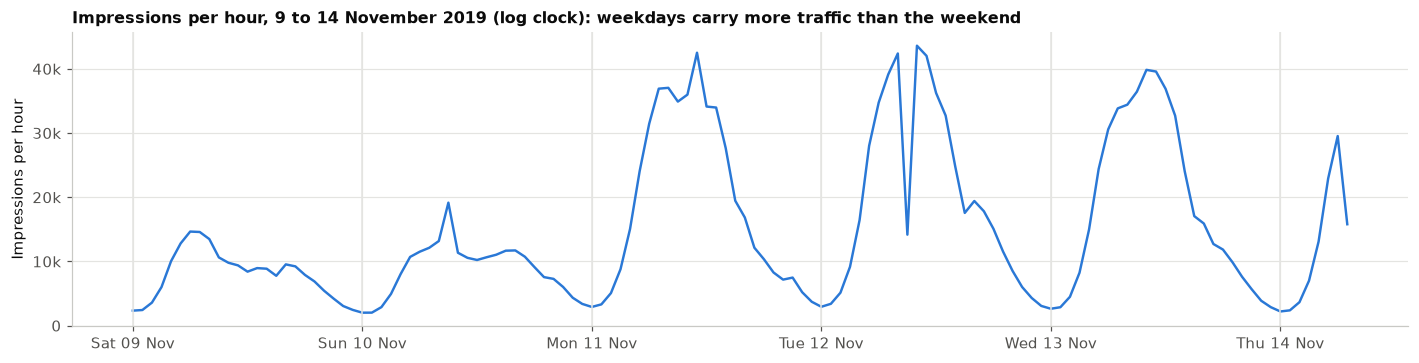

*art_06_hourly_volume.png — Hourly impression volume, training split.*

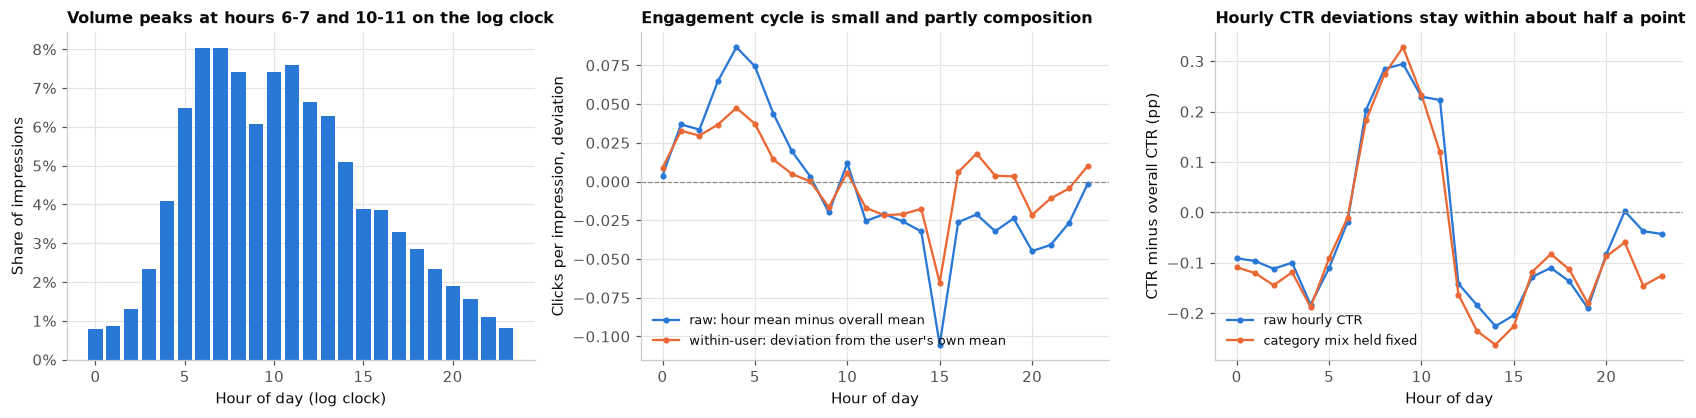

*art_06_hour_of_day.png — Hour-of-day volume and engagement, training split.*

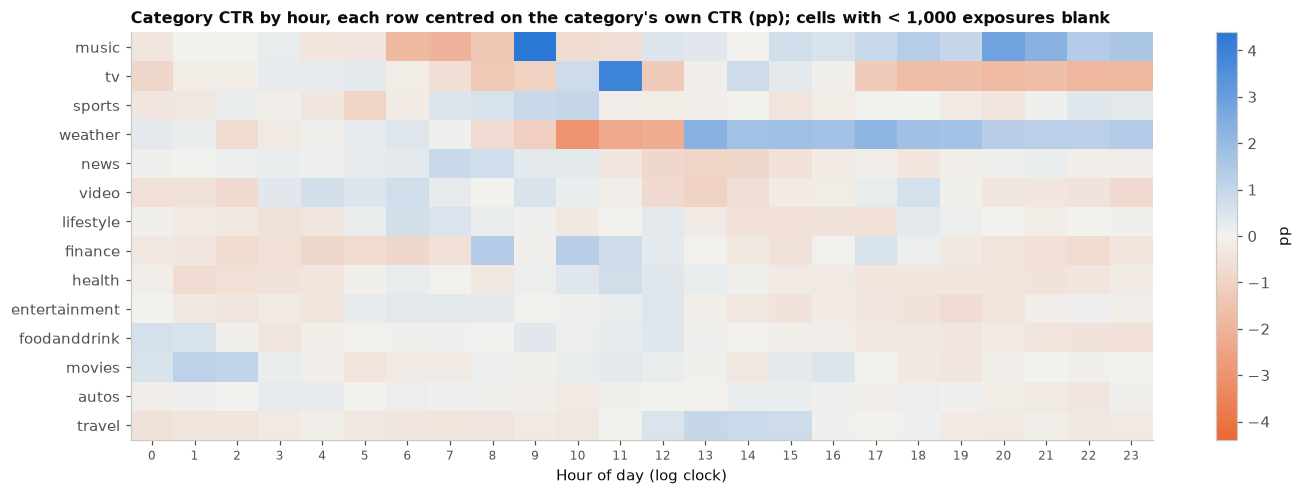

*art_06_category_hour_heatmap.png — Shared diurnal pattern across categories, training split.*

In [9]:
t0 = time.time()
hourly = (imp.group_by(pl.col("timestamp").dt.truncate("1h").alias("hour")).agg(impressions=pl.len(), clicks=pl.col("n_clicks").cast(pl.Int64).sum(), exposures=pl.col("slate_len").cast(pl.Int64).sum())
          .with_columns(clicks_per_impression=pl.col("clicks") / pl.col("impressions"), ctr_pct=100 * pl.col("clicks") / pl.col("exposures")).sort("hour").to_pandas())
save_table("art_06_hourly_timeline", hourly)
daily = imp.group_by(pl.col("timestamp").dt.date().alias("date")).agg(impressions=pl.len(), users=pl.col("user_code").n_unique(), clicks=pl.col("n_clicks").cast(pl.Int64).sum(), exposures=pl.col("slate_len").cast(pl.Int64).sum()).with_columns(ctr_pct=100 * pl.col("clicks") / pl.col("exposures")).sort("date").to_pandas()
display(save_table("art_06_daily_volume", daily)); H["daily"] = daily.astype({"date": str}).round(3).to_dict("records")
multi = imp.filter(pl.len().over("user_code") > 1).with_columns(dev=pl.col("n_clicks") - pl.col("n_clicks").mean().over("user_code"), hour=pl.col("timestamp").dt.hour())
hod = (imp.with_columns(hour=pl.col("timestamp").dt.hour()).group_by("hour").agg(impressions=pl.len(), clicks=pl.col("n_clicks").cast(pl.Int64).sum(), exposures=pl.col("slate_len").cast(pl.Int64).sum())
       .join(multi.group_by("hour").agg(within_user_dev=pl.col("dev").mean()), on="hour").sort("hour")
       .with_columns(impression_pct=100 * pl.col("impressions") / pl.col("impressions").sum(), clicks_per_impression=pl.col("clicks") / pl.col("impressions"), ctr_pct=100 * pl.col("clicks") / pl.col("exposures")))
hod = hod.with_columns(raw_dev=pl.col("clicks_per_impression") - H["n_clicks"] / H["n_impressions"]).to_pandas()
# category-adjusted hourly CTR: hold the category mix fixed at its overall share
ch = (cand.lazy().join(cat_map.lazy(), on="news_code", how="left").with_columns(hour=pl.col("timestamp").dt.hour()).group_by("hour", "category").agg(exposures=pl.len(), clicks=pl.col("clicked").cast(pl.Int64).sum())
      .with_columns(ctr=pl.col("clicks") / pl.col("exposures")).collect())
cat_share = ch.group_by("category").agg(exposures=pl.col("exposures").sum(), clicks=pl.col("clicks").sum()).with_columns(share=pl.col("exposures") / pl.col("exposures").sum(), category_ctr=pl.col("clicks") / pl.col("exposures"))
adj = (ch.join(cat_share.select("category", "share"), on="category").filter(pl.col("exposures") >= 1000).group_by("hour").agg(adjusted_ctr_pct=100 * (pl.col("share") * pl.col("ctr")).sum() / pl.col("share").sum()).sort("hour").to_pandas())
hod = hod.merge(adj, on="hour", how="left"); hod["raw_ctr_dev_pp"] = hod.ctr_pct - H["ctr_overall"]; hod["adjusted_ctr_dev_pp"] = hod.adjusted_ctr_pct - H["ctr_overall"]
display(save_table("art_06_hour_of_day", hod))
H["corr_raw_vs_within_user_hourly"] = float(np.corrcoef(hod.raw_dev, hod.within_user_dev)[0, 1])
H["peak_volume_hour"], H["within_user_max_hour"], H["within_user_min_hour"] = int(hod.loc[hod.impressions.idxmax(), "hour"]), int(hod.loc[hod.within_user_dev.idxmax(), "hour"]), int(hod.loc[hod.within_user_dev.idxmin(), "hour"])
H["within_user_dev_range"] = [float(hod.within_user_dev.min()), float(hod.within_user_dev.max())]
# category x hour heatmap, each row centred on the category's own CTR
major = cat_share.filter(pl.col("exposures") >= 100_000).sort("category_ctr", descending=True)["category"].cast(pl.Utf8).to_list()
heat = (ch.join(cat_share.select("category", "category_ctr"), on="category").filter(pl.col("exposures") >= 1000).with_columns(dev_pp=100 * (pl.col("ctr") - pl.col("category_ctr")))
        .with_columns(pl.col("category").cast(pl.Utf8)).to_pandas().pivot(index="category", columns="hour", values="dev_pp").reindex(index=major, columns=range(24)))
save_table("art_06_category_hour_deviation", heat.reset_index())
print(f"Peak volume at hour {H['peak_volume_hour']}; within-user clicks per impression highest at hour {H['within_user_max_hour']}, lowest at {H['within_user_min_hour']} "
      f"(range {H['within_user_dev_range'][0]:+.3f} to {H['within_user_dev_range'][1]:+.3f}); corr(raw, within-user) = {H['corr_raw_vs_within_user_hourly']:.2f} · {time.time() - t0:.0f} s")

fig, ax = plt.subplots(figsize=(13, 3.4))
ax.plot(hourly.hour, hourly.impressions, color=BLUE, lw=1.6)
for d_ in pd.to_datetime(daily.date):
    ax.axvline(d_, color=GRID, lw=1)
ax.set_ylabel("Impressions per hour"); ax.yaxis.set_major_formatter(THOUSANDS); ax.set_title("Impressions per hour, 9 to 14 November 2019 (log clock): weekdays carry more traffic than the weekend")
ax.xaxis.set_major_formatter(matplotlib.dates.DateFormatter("%a %d %b")); fig.tight_layout(); save_fig(fig, "art_06_hourly_volume", "Hourly impression volume, training split.")

fig, axes = plt.subplots(1, 3, figsize=(15.5, 3.9))
axes[0].bar(hod.hour, hod.impression_pct, color=BLUE); axes[0].set_xlabel("Hour of day (log clock)"); axes[0].set_ylabel("Share of impressions"); axes[0].yaxis.set_major_formatter(PCT); axes[0].set_title("Volume peaks at hours 6-7 and 10-11 on the log clock")
axes[1].plot(hod.hour, hod.raw_dev, marker="o", ms=3, color=BLUE, label="raw: hour mean minus overall mean")
axes[1].plot(hod.hour, hod.within_user_dev, marker="o", ms=3, color=ORANGE, label="within-user: deviation from the user's own mean")
axes[1].axhline(0, color=REF, ls="--", lw=0.8); axes[1].set_xlabel("Hour of day"); axes[1].set_ylabel("Clicks per impression, deviation"); axes[1].legend(loc="lower left"); axes[1].set_title("Engagement cycle is small and partly composition")
axes[2].plot(hod.hour, hod.raw_ctr_dev_pp, marker="o", ms=3, color=BLUE, label="raw hourly CTR")
axes[2].plot(hod.hour, hod.adjusted_ctr_dev_pp, marker="o", ms=3, color=ORANGE, label="category mix held fixed")
axes[2].axhline(0, color=REF, ls="--", lw=0.8); axes[2].set_xlabel("Hour of day"); axes[2].set_ylabel("CTR minus overall CTR (pp)"); axes[2].legend(loc="lower left"); axes[2].set_title("Hourly CTR deviations stay within about half a point")
fig.tight_layout(); save_fig(fig, "art_06_hour_of_day", "Hour-of-day volume and engagement, training split.")

fig, ax = plt.subplots(figsize=(13, 4.6))
vlim = np.nanmax(np.abs(heat.values)); im = ax.imshow(heat.values, cmap=DIVERGING, vmin=-vlim, vmax=vlim, aspect="auto"); ax.grid(False)
ax.set_xticks(range(24)); ax.set_xticklabels(range(24), fontsize=8); ax.set_yticks(range(len(major))); ax.set_yticklabels(major); ax.set_xlabel("Hour of day (log clock)")
ax.set_title("Category CTR by hour, each row centred on the category's own CTR (pp); cells with < 1,000 exposures blank")
fig.colorbar(im, ax=ax, label="pp"); fig.tight_layout(); save_fig(fig, "art_06_category_hour_heatmap", "Shared diurnal pattern across categories, training split.")

**Reading.** Volume follows a strong daily cycle (peaks at hours 6-7 and 10-11 on the log clock, which is not a documented local time) and
is more than twice as high on the weekdays (11 to 14 November) as on the weekend. Engagement per visit moves far less: the within-user deviation
stays within ±0.07 clicks around a mean of 1.5 (highest at hour 4, lowest at hour 15), tracking the raw curve (correlation 0.9), and hourly CTR
deviations remain within a third of a percentage point whether or not the category mix is held fixed. All
categories share the same diurnal banding; isolated category-hour cells that stand out are single-day content events driven by a handful of
articles.

**Implications.** Hour of day is a cheap context feature that captures when users are more engaged, but it will mostly improve calibration
rather than ranking because it does not separate candidates within a slate. Model it as a coarse day-part, optionally interacted with category.

## 7. Time since the user's previous impression

Every user's first impression in the window has no gap; the 5.3-day window right-censors long gaps. Engagement is clicks per impression, raw
and within-user demeaned; redundancy with hour of day and history length is checked.

,gap_group,impressions,clicks_per_impression,mean_slate_len,ctr_pct,within_user_dev,raw_dev
0,<1 hour,198697,1.4502,34.3264,4.2247,-0.0398,-0.0898
1,1-6 hours,313092,1.5475,37.4854,4.1284,-0.0369,0.0076
2,6-24 hours,406358,1.6068,38.0585,4.2220,0.0379,0.0669
3,1-3 days,286677,1.5084,37.1265,4.0627,0.0178,-0.0316
4,>3 days,25131,1.4338,37.4037,3.8332,0.0193,-0.1062


First impressions (no gap): 35.2%; median gap 11.7 h; 75% of gaps < 24 h; Spearman(gap, hour) = -0.07, Spearman(gap, history length) = -0.22


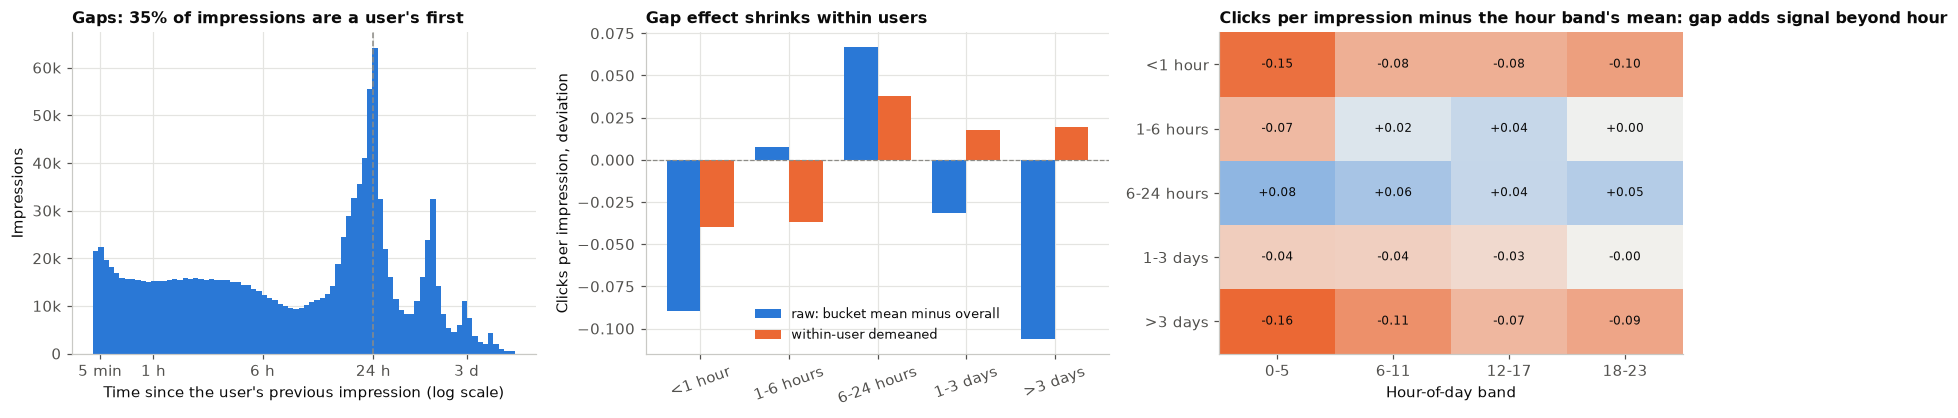

*art_07_recency_gap.png — Time since the previous impression, training split.*

In [10]:
GAP_ORDER = ["<1 hour", "1-6 hours", "6-24 hours", "1-3 days", ">3 days"]
gaps = (imp.sort("user_code", "timestamp").with_columns(gap_h=pl.col("timestamp").diff().over("user_code").dt.total_seconds() / 3600, hour=pl.col("timestamp").dt.hour()))
H["first_impression_pct"] = 100 * float(gaps["gap_h"].is_null().mean())
g = gaps.drop_nulls("gap_h").with_columns(gap_group=bucket("gap_h", [1, 6, 24, 72], GAP_ORDER))
q = {f"p{int(p*100)}": float(g["gap_h"].quantile(p)) for p in [0.1, 0.25, 0.5, 0.75, 0.9]}
below = {t: 100 * float((g["gap_h"] < h).mean()) for t, h in [("<5 min", 1/12), ("<1 hour", 1), ("<6 hours", 6), ("<24 hours", 24), ("<72 hours", 72)]}
H["gap_quantiles_h"], H["gap_share_below"] = q, below
cps = (g.group_by("gap_group").agg(impressions=pl.len(), clicks_per_impression=pl.col("n_clicks").mean(), mean_slate_len=pl.col("slate_len").mean(), ctr_pct=100 * pl.col("n_clicks").cast(pl.Int64).sum() / pl.col("slate_len").cast(pl.Int64).sum()))
gm = g.filter(pl.len().over("user_code") > 1).with_columns(dev=pl.col("n_clicks") - pl.col("n_clicks").mean().over("user_code"))
dem = gm.group_by("gap_group").agg(within_user_dev=pl.col("dev").mean())
gap_tbl = ordered(cps.join(dem, on="gap_group"), "gap_group", GAP_ORDER); overall = float(g["n_clicks"].mean()); gap_tbl["raw_dev"] = gap_tbl.clicks_per_impression - overall
display(save_table("art_07_clicks_by_gap", gap_tbl)); H["gap_table"] = gap_tbl.round(4).to_dict("records")
H["spearman_gap_hour"] = float(g.select(pl.corr("gap_h", "hour", method="spearman")).item()); H["spearman_gap_history"] = float(g.select(pl.corr("gap_h", "history_len", method="spearman")).item())
band = g.with_columns(hour_band=pl.when(pl.col("hour") < 6).then(pl.lit("0-5")).when(pl.col("hour") < 12).then(pl.lit("6-11")).when(pl.col("hour") < 18).then(pl.lit("12-17")).otherwise(pl.lit("18-23")))
within = (band.group_by("hour_band", "gap_group").agg(impressions=pl.len(), cpi=pl.col("n_clicks").mean()).join(band.group_by("hour_band").agg(band_cpi=pl.col("n_clicks").mean()), on="hour_band")
          .with_columns(dev=pl.col("cpi") - pl.col("band_cpi")).to_pandas())
heat = within.pivot(index="gap_group", columns="hour_band", values="dev").reindex(index=GAP_ORDER, columns=["0-5", "6-11", "12-17", "18-23"])
save_table("art_07_gap_by_hour_band", heat.reset_index())
print(f"First impressions (no gap): {H['first_impression_pct']:.1f}%; median gap {q['p50']:.1f} h; {below['<24 hours']:.0f}% of gaps < 24 h; Spearman(gap, hour) = {H['spearman_gap_hour']:.2f}, Spearman(gap, history length) = {H['spearman_gap_history']:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(15.5, 3.9))
lg = np.log1p(g["gap_h"].to_numpy()); ticks = np.log1p([1/12, 1, 6, 24, 72])
axes[0].hist(lg, bins=80, color=BLUE); axes[0].axvline(np.log1p(24), color=REF, ls="--", lw=1); axes[0].set_xticks(ticks); axes[0].set_xticklabels(["5 min", "1 h", "6 h", "24 h", "3 d"])
axes[0].set_xlabel("Time since the user's previous impression (log scale)"); axes[0].set_ylabel("Impressions"); axes[0].yaxis.set_major_formatter(THOUSANDS); axes[0].set_title(f"Gaps: {H['first_impression_pct']:.0f}% of impressions are a user's first")
x = np.arange(5); w = 0.38
axes[1].bar(x - w/2, gap_tbl.raw_dev, width=w, color=BLUE, label="raw: bucket mean minus overall"); axes[1].bar(x + w/2, gap_tbl.within_user_dev, width=w, color=ORANGE, label="within-user demeaned")
axes[1].axhline(0, color=REF, ls="--", lw=0.8); axes[1].set_xticks(x); axes[1].set_xticklabels(GAP_ORDER, rotation=20); axes[1].set_ylabel("Clicks per impression, deviation"); axes[1].legend(); axes[1].set_title("Gap effect shrinks within users")
vlim = np.nanmax(np.abs(heat.values)); im = axes[2].imshow(heat.values, cmap=DIVERGING, vmin=-vlim, vmax=vlim, aspect="auto"); axes[2].grid(False)
axes[2].set_xticks(range(4)); axes[2].set_xticklabels(["0-5", "6-11", "12-17", "18-23"]); axes[2].set_yticks(range(5)); axes[2].set_yticklabels(GAP_ORDER)
for i in range(5):
    for j in range(4): axes[2].text(j, i, f"{heat.values[i, j]:+.2f}", ha="center", va="center", fontsize=8, color=INK)
axes[2].set_xlabel("Hour-of-day band"); axes[2].set_title("Clicks per impression minus the hour band's mean: gap adds signal beyond hour")
fig.tight_layout(); save_fig(fig, "art_07_recency_gap", "Time since the previous impression, training split.")

**Reading.** Two thirds of impressions have a previous visit in the window; the median gap is about 12 hours and 75 % of gaps are under a day.
Clicks per visit peak after a 6 to 24 hour gap and are lowest for immediate continuations and for returns after more than 3 days; within users
the spread shrinks to about ±0.04 clicks and the long-gap penalty disappears, so much of the raw pattern is user composition. The gap is only
weakly related to hour of day and moderately to history length, and its gradient persists inside hour bands.

**Implications.** `hours_since_previous_impression` is a small but consistent session feature (plus a first-visit indicator); like hour of
day it mostly informs calibration. The short-term versus long-term interest split that depends on the gap is examined in `user_analysis`.

## 8. What this notebook decides

| Finding | Evidence | Decision |
|---|---|---|
| Short text, 5 % missing abstracts, 25 % no entities; subcategory long tail | §1 | title-first encoder (20 / 100 tokens), abstract mask, entity path optional, embed subcategory |
| 3 % of shown articles take 80 % of clicks; raw CTR unstable below 100 exposures | §2 | prior exposures / clicks / smoothed CTR, never whole-window CTR |
| Category CTR spread survives exposure control | §3 | `category` feature, compact encoding, cold-start fallback |
| CTR decays with article age; prior clicks matter at the head | §4 | `article_age_hours` + censoring flag, category-specific decay, time-causal popularity updated hourly |
| 70 % of test-day exposures (76 % of clicks) are on articles unseen in train | §5 | content-based candidate generation; popularity must update through the test day |
| Time of day moves volume, not engagement | §6 | coarse day-part context feature, calibration not ranking |
| Gap effect small and partly composition | §7 | recency feature with first-visit flag, low priority |

In [11]:
manifest["tables"] = sorted(set(manifest["tables"])); manifest["figures"] = sorted(set(manifest["figures"]))
(EDA_DIR / f"manifest_{NOTEBOOK_NAME}.json").write_text(json.dumps(manifest, indent=2, default=str))
print(f"{len(manifest['figures'])} figures in {FIG_DIR}\n{len(manifest['tables'])} tables in {TABLE_DIR}\nheadline numbers -> manifest_{NOTEBOOK_NAME}.json")

9 figures in /Users/bryan03/Desktop/BT4222-Group-6-/2_EDA/figures
15 tables in /Users/bryan03/Desktop/BT4222-Group-6-/2_EDA/tables
headline numbers -> manifest_article_temporal_analysis.json
